# RTENSO2026: animated evolution of the 2026/27 El Niño

Month-by-month animation of the 2026/27 El Niño in the E3SM RTENSO2026 hindcasts from the
1 Feb, 1 May and 1 Aug 2026 starts, next to the observations. Each frame is one target month:

* **Maps** (global Robinson centred on the Pacific; set `DOMAIN` to a box for a regional
  PlateCarree map): the observed anomaly and the pooled ensemble-mean
  anomaly from each start. A panel is blank before its start month, and the observed panel is
  blank once the target month is past the latest observation. The dashed box is Niño3.4.
* **Niño3.4 panel**: each start's ensemble mean (thick) and member range (shading) drawn up to the
  frame month, with the rest of the forecast faded; the observed index (black) up to the latest
  month; the cursor marks the frame month. Dashed lines are the XRO reference forecasts (`XRO_REFERENCE`):
  the deterministic XRO (Zhao et al. 2024; the control setup of 7b, `xc.XRO_SETUP`, trained on 1981-2025)
  started from the observed state (HadISST 1.1 SST, EN4.2.2 heat content) of the month before each start.

One animation per field in `ANIM_FIELDS` (SST, 0-700 m heat content as the recharge proxy,
precipitation, and 2-m air temperature over land), saved as GIF (slides, web pages) and a video (H.264 MP4 when ffmpeg supports it, else
VP9 WebM; smaller, for talks), plus a static
storyboard of selected months for papers.

Anomalies are as in the other notebooks: the model removes the Reanalysis 1981-2010 lead-time
climatology (`CLIM_METHOD`, lead-drift corrected for the Feb/Aug starts) and each observed product
its own 1981-2010 monthly climatology. Observations: NOAA OISST v2.1 for SST and the observed Niño3.4,
EN4.2.2 for OHC700, GPCP v2.3 for precipitation and ERA5-Land for 2-m air temperature (land only; the
model is masked to land to match), each through its latest month (printed when
loaded; the observation caches rebuild when an archive product is extended).

**Pooled ensembles:** each start pools the members of the `POOL` cases (`Reanalysis-CLIM`,
`-OBS`, `-NSIDC`; 30 members). The 1 Feb 2026 `clim` and `obs` runs are bit-identical (see
"1 Feb 2026 start" in `README.md`), so that start pools 20 members.

The pooled ensemble means over `DOMAIN` are cached under `data/` (`derivation_mode`), so re-styling
the animations does not re-read the hindcasts.

In [1]:
%matplotlib inline

import subprocess
import warnings
from datetime import datetime

import numpy as np
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from IPython.display import Image, display
from matplotlib import animation
from matplotlib.colors import BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from cartopy.util import add_cyclic_point
from esp_lab.utils import colormap_utils as mycolors
from esp_lab.utils.filename_utils import figure_filename
from esp_lab.utils.netcdf_utils import atomic_to_netcdf

from util import rtenso_case as rc
from util import xro_case as xc

warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Mean of empty slice")

### Run controls

In [2]:
NOTEBOOK = "8_enso2026_animation"   # outputs: rc.OUTPUT_ROOT/8_enso2026_animation/{figures,data}/
# "auto": reuse the pooled ensemble-mean caches; "rebuild": re-read the hindcasts; "require": fail if a cache is missing
derivation_mode = "auto"
CLIM_METHOD = "lead_drift"          # Feb/Aug drift correction: "lead_drift" or "target_month"

YEAR = 2026
EVENT_LABEL = "2026/27 El Niño"
INIT_MONTHS = (2, 5, 8)
MONTH_NAMES = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}
INIT_COLORS = {2: "#1f77b4", 5: "#2ca02c", 8: "#d62728"}   # one colour per start (maps' titles and the Nino3.4 panel)

# First and last target month animated (the Aug start runs to Jul 2028)
FRAMES = ((2026, 1), (2027, 12))
# Months shown in the static storyboard (one row each)
STORYBOARD = [(2026, 3), (2026, 6), (2026, 9), (2026, 12), (2027, 3), (2027, 6)]

# Members pooled per start. A case whose members repeat an already pooled case member for member
# (the 1 Feb 2026 clim and obs runs) is counted once.
MODEL_PREFIX = "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5"
POOL = {
    "Reanalysis-CLIM": f"{MODEL_PREFIX}_RTENSO2026_clim",
    "Reanalysis-OBS": f"{MODEL_PREFIX}_RTENSO2026_obs",
    "Reanalysis-NSIDC": f"{MODEL_PREFIX}_RTENSO2026_obs_ice_nsidc",
}

ANIM_FIELDS = ["TS", "OHC700", "PRECT", "TREFHT"]
# Observation product per field (missing: rc default with its archive fallback: EN4.2.2 OHC700, GPCP v2.3 PRECT)
OBS_PRODUCT = {"TS": "OISSTv2.1", "TREFHT": "ERA5_Land"}   # ERA5-Land: land only (ERA5 itself ends in 2019 here)
INDEX = "Nino3.4"
INDEX_PRODUCT = "OISSTv2.1"         # observed Nino3.4
# Map domain [lon0, lon1, lat0, lat1] (0-360 longitudes). A full 360 deg span draws global Robinson maps centred on
# 180; a box (e.g. [100, 290, -30, 30], the tropical Indo-Pacific) draws a regional PlateCarree map.
DOMAIN = [0.0, 360.0, -90.0, 90.0]

STYLE = {
    # name, shading interval and range, contour-line interval (None: no lines), colormap, units, ocean only / land only
    "TS": {"name": "SST anomaly", "ci": 0.25, "range": 3.0, "line": 1.0, "cmap": "blue2red",
           "units": "°C", "ocean": True, "lat_max": 60.0},   # lat_max: blank poleward (sea ice), as in notebook 2
    "OHC700": {"name": "0-700 m heat content anomaly", "ci": 0.25, "range": 4.0, "line": 1.0, "cmap": "blue2red",
               "units": "GJ m$^{-2}$", "ocean": True},
    "PRECT": {"name": "Precipitation anomaly", "ci": 1.0, "range": 8.0, "line": None, "cmap": "BrBG",
              "units": "mm day$^{-1}$", "ocean": False},
    "TREFHT": {"name": "2-m air temperature anomaly", "ci": 0.5, "range": 5.0, "line": None, "cmap": "blue2red",
               "units": "°C", "ocean": False, "land": True},   # land only, as the ERA5-Land observations
}
NINO_YLIM = (-2.5, 5.5)    # holds every member range (-2.2 to 5.1 degC); None: fit the ranges, observed index and XRO in FRAMES (to 0.5 degC)
# XRO reference in the Nino3.4 panel: "det" (deterministic forecast, dashed in each start's colour) or None
XRO_REFERENCE = "det"
NINO_THRESHOLDS = {0.5: "El Niño", 1.5: "strong", 2.0: "very strong"}

# Animation output
FPS = 2                    # frames (months) per second
HOLD = 4                   # extra copies of the last frame, so a looping GIF pauses at the end
ANIM_DPI = 110             # 12 x 8 in at 110 dpi: 1320 x 880 px
# "gif" (Pillow) and "video": H.264 MP4 when ffmpeg has libx264 (e.g. `pip install imageio-ffmpeg`, picked up
# automatically), else VP9 WebM (the NERSC system ffmpeg 3.4 has no H.264 encoder); skipped without ffmpeg
ANIM_FORMATS = ("gif", "video")
SHOW_INLINE = "TS"         # field whose GIF is shown in the notebook (None: none)
fig_dpi = 300              # static storyboard

OUTDIR = rc.output_dir(NOTEBOOK, "data")
FIGDIR = rc.figure_dir(NOTEBOOK)

### Load observations and pooled hindcasts

Everything is reduced to `DOMAIN` and keyed by target month (`datetime(y, m, 15)`). The hindcast
products (pooled ensemble mean per start, and for `TS` the member Niño3.4) are cached as netCDF.

In [3]:
GLOBAL = DOMAIN[1] - DOMAIN[0] >= 360.0


def to_datetime(times):
    return [datetime(t.year, t.month, 15) for t in np.atleast_1d(times)]


def month_label(t, fmt="%b %Y"):
    return t.strftime(fmt)


def frame_months(first, last):
    months, (y, m) = [], first
    while (y, m) <= last:
        months.append(datetime(y, m, 15))
        y, m = (y + 1, 1) if m == 12 else (y, m + 1)
    return months


def pool_cache(field, init):
    tag = "global" if GLOBAL else "{:g}-{:g}E_{:g}-{:g}N".format(*DOMAIN)
    return OUTDIR / f"RTENSO2026_pool_init{init:02d}_{field}_y{YEAR}_{CLIM_METHOD}_ensmean_{tag}.nc"


def pooled_hindcast(field, init):
    # Pooled ensemble over DOMAIN: Dataset with ens_mean (lead, lat, lon), n_members, and for TS the
    # member index (member, lead). Cached; None when no POOL case has the start.
    path = pool_cache(field, init)
    if derivation_mode != "rebuild" and path.exists():
        return xr.open_dataset(path).load()
    if derivation_mode == "require":
        raise FileNotFoundError(path)
    members, cases, index = [], [], []
    for case, prefix in POOL.items():
        anom = rc.hindcast_anomaly(prefix, init, field, year=YEAR, method=CLIM_METHOD, mode="auto")
        if anom is None:
            print(f"[{field} init{init:02d} {case}] not available")
            continue
        sub = rc.region_subset(anom, DOMAIN).load()
        if any(np.array_equal(sub.values, m.values, equal_nan=True) for m in members):
            print(f"[{field} init{init:02d} {case}] repeats an already pooled case member for member; not pooled again")
            continue
        members.append(sub)
        cases.append(case)
        if field == "TS":
            index.append(rc.box_mean(sub, rc.NINO_REGIONS[INDEX]).assign_coords(
                member=[f"{case}:{m}" for m in sub["member"].values]))
    if not members:
        return None
    pooled = xr.concat(members, dim="member")
    ds = xr.Dataset({"ens_mean": pooled.mean("member")})
    if index:
        ds["nino"] = xr.concat(index, dim="member")
    target = [t.year * 100 + t.month for t in pooled["time"].values]
    ds = ds.drop_vars("time", errors="ignore").assign_coords(target=("lead", target))
    ds.attrs.update(n_members=pooled.sizes["member"], cases=", ".join(cases), init_year=YEAR, init_month=init,
                    field=field, climatology_method=CLIM_METHOD, units=rc.FIELDS[field]["units"])
    atomic_to_netcdf(ds, path)
    return ds


def by_target(da):
    # lead -> time (datetime) from the cached yyyymm target coordinate
    times = [datetime(int(t) // 100, int(t) % 100, 15) for t in da["target"].values]
    return da.assign_coords(time=("lead", times)).swap_dims(lead="time").drop_vars(["lead", "target"])

In [4]:
%%time
span = (YEAR - 1, YEAR + 2)
ocean = rc.region_subset(rc.land_fraction() < 0.5, DOMAIN)

obs, fc, n_members = {}, {}, {}   # field -> (time, lat, lon); (field, init) -> (time, lat, lon); init -> members
for field in ANIM_FIELDS:
    o = rc.region_subset(rc.obs_anomaly(field, years=span, mode=derivation_mode, product=OBS_PRODUCT.get(field)), DOMAIN)
    o = o.assign_coords(time=to_datetime(o["time"].values))
    if "lat_max" in STYLE[field]:
        o = o.where(abs(o["lat"]) <= STYLE[field]["lat_max"])
    obs[field] = o.isel(time=o.notnull().any(("lat", "lon")).values).load()
    obs[field].attrs["product"] = o.attrs.get("product", OBS_PRODUCT.get(field, ""))
    print(f"[{field}] {obs[field].attrs['product']} observed through {month_label(obs[field]['time'].values[-1].astype('M8[ms]').item())}")
    for init in INIT_MONTHS:
        ds = pooled_hindcast(field, init)
        if ds is None:
            continue
        mean = by_target(ds["ens_mean"])
        if STYLE[field]["ocean"]:
            mean = mean.where(ocean)
        if STYLE[field].get("land"):
            mean = mean.where(~ocean)
        if "lat_max" in STYLE[field]:
            mean = mean.where(abs(mean["lat"]) <= STYLE[field]["lat_max"])
        fc[(field, init)] = mean
        n_members[init] = int(ds.attrs["n_members"])
        print(f"[{field} init{init:02d}] {ds.attrs['n_members']} members ({ds.attrs['cases']})")

# Nino3.4: observed (INDEX_PRODUCT) and each start's members
o = rc.obs_anomaly("TS", years=span, mode=derivation_mode, product=INDEX_PRODUCT)
obs_nino = rc.box_mean(o, rc.NINO_REGIONS[INDEX]).dropna("time").load()
obs_nino = obs_nino.assign_coords(time=to_datetime(obs_nino["time"].values))
fc_nino = {}   # init -> member Nino3.4 (member, time)
for init in INIT_MONTHS:
    ds = pooled_hindcast("TS", init)
    if ds is not None:
        fc_nino[init] = by_target(ds["nino"])
# XRO reference: the 7b control forecast for each start (lead 0 = start month)
xro_nino = {}   # init -> Nino3.4 (time)
if XRO_REFERENCE:
    X_obs = xc.obs_state(mode=derivation_mode)
    xfit = xc.fit_xro(X_obs, xc.EVENTS[YEAR]["train"])
    for init in fc_nino:
        xfc = xc.event_forecast(xfit, YEAR, init, stochastic=False)
        if xfc is None:
            print(f"[XRO init{init:02d}] no fully observed initial state")
            continue
        det = xfc[XRO_REFERENCE]["Nino34"].sel(lead=slice(0, None))
        xro_nino[init] = det.swap_dims(lead="time").assign_coords(time=to_datetime(det["time"].values)).drop_vars("lead")
        print(f"[XRO init{init:02d}] peak {float(xro_nino[init].max()):.2f} C in "
              f"{month_label(xro_nino[init]['time'].values[int(xro_nino[init].argmax())].astype('M8[ms]').item())}")
for init, nino in fc_nino.items():
    peak = nino.mean("member")
    print(f"[{INDEX} init{init:02d}] ensemble-mean peak {float(peak.max()):.2f} C in "
          f"{month_label(peak['time'].values[int(peak.argmax())].astype('M8[ms]').item())}")

[TS] OISSTv2.1 observed through Oct 2026
[TS init02] 20 members (Reanalysis-CLIM, Reanalysis-NSIDC)
[TS init05] 30 members (Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC)
[TS init08] 30 members (Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC)
[OHC700] EN4.2.2 observed through Aug 2026
[OHC700 init02] 20 members (Reanalysis-CLIM, Reanalysis-NSIDC)
[OHC700 init05] 30 members (Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC)
[OHC700 init08] 30 members (Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC)


[PRECT] GPCP_v2.3 observed through Jun 2026
[PRECT init02] 20 members (Reanalysis-CLIM, Reanalysis-NSIDC)
[PRECT init05] 30 members (Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC)
[PRECT init08] 30 members (Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC)
[TREFHT] ERA5_Land observed through Sep 2026
[TREFHT init02] 20 members (Reanalysis-CLIM, Reanalysis-NSIDC)
[TREFHT init05] 30 members (Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC)
[TREFHT init08] 30 members (Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC)


[XRO init02] peak 0.63 C in Jan 2027
[XRO init05] peak 3.08 C in Jan 2027
[XRO init08] peak 3.90 C in Dec 2026
[Nino3.4 init02] ensemble-mean peak 2.61 C in Jan 2027
[Nino3.4 init05] ensemble-mean peak 3.81 C in Dec 2026
[Nino3.4 init08] ensemble-mean peak 4.68 C in Dec 2026
CPU times: user 1.7 s, sys: 447 ms, total: 2.15 s
Wall time: 2.23 s


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/xarray/core/dataarray.py:6439: FutureWarning: Behaviour of argm

### Frame layout

One figure per field: a 2 x 2 block of maps (observed, then the starts in order) above the Niño3.4
panel. `draw_frame` redraws only what changes between months, so the same function draws the
animation frames and the preview below.

In [5]:
FIG = {
    "size": (12.0, 9.6),            # inches; the animation is saved at ANIM_DPI (keep pixel sizes even for video)
    "height_ratios": (1.0, 1.0, 0.05, 0.75),   # map row, map row, colorbar, Nino3.4 panel
    "hspace": 0.42, "wspace": 0.06,
    "left": 0.05, "right": 0.97, "top": 0.88, "bottom": 0.10,
    "suptitle": 17, "month": 22, "title": 11.5, "label": 11, "tick": 10, "legend": 10, "badge": 10.5,
    "coast_lw": 0.6, "land": "0.82", "empty": "0.93",
    "ens_lw": 2.6, "xro_lw": 1.6, "obs_lw": 2.4, "faded_alpha": 0.22, "range_alpha": 0.18,
}
NINO_BOX = rc.NINO_REGIONS[INDEX]
PROJ = ccrs.Robinson(central_longitude=180) if GLOBAL else ccrs.PlateCarree(central_longitude=180)


def levels_cmap(style):
    levels = np.arange(-style["range"], style["range"] + style["ci"] / 2, style["ci"])
    cmap = mycolors.blue2red_cmap(levels) if style["cmap"] == "blue2red" else plt.get_cmap(style["cmap"], len(levels) - 1)
    return levels, cmap, BoundaryNorm(levels, ncolors=cmap.N)   # beyond the range: the end colours


def setup_map(ax, title, color="k", left=True, bottom=True, land_only=False):
    # grey land beneath the shading: it shows where a field has no values (SST, OHC700), not over precipitation
    ax.add_feature(cfeature.LAND, facecolor=FIG["land"], zorder=0.5)
    if land_only:   # a land-only field: grey ocean, so it is not read as a zero anomaly
        ax.add_feature(cfeature.OCEAN, facecolor=FIG["land"], zorder=0.5)
    ax.coastlines(lw=FIG["coast_lw"], zorder=3)
    ax.add_patch(Rectangle((NINO_BOX[0], NINO_BOX[2]), NINO_BOX[1] - NINO_BOX[0], NINO_BOX[3] - NINO_BOX[2],
                           transform=ccrs.PlateCarree(), fill=False, ec="k", lw=1.0, ls="--", zorder=4))
    if GLOBAL:   # no labels: the Robinson outline is enough
        ax.set_global()
        ax.gridlines(crs=ccrs.PlateCarree(), lw=0.3, color="0.5", alpha=0.5,
                     xlocs=range(-180, 181, 60), ylocs=range(-60, 61, 30))
    else:
        ax.set_extent(DOMAIN, crs=ccrs.PlateCarree())
        gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, lw=0.3, color="0.5", alpha=0.6,
                          xlocs=[120, 160, -160, -120, -80], ylocs=[-30, -15, 0, 15, 30])
        gl.top_labels = gl.right_labels = False
        gl.left_labels, gl.bottom_labels = left, bottom
        gl.xlabel_style = gl.ylabel_style = {"size": FIG["tick"] - 1}
    ax.set_title(title, loc="left", fontsize=FIG["title"], color=color, fontweight="bold")
    state = {"artists": [], "lead": ax.set_title("", loc="right", fontsize=FIG["title"], color=color),
             "empty": ax.text(0.5, 0.5, "", transform=ax.transAxes, ha="center", va="center", fontsize=FIG["label"],
                              color="0.35", zorder=6,
                              bbox={"facecolor": "white", "edgecolor": "0.6", "boxstyle": "round,pad=0.4"}),
             "badge": ax.text(0.015, 0.05, "", transform=ax.transAxes, ha="left", va="bottom", fontsize=FIG["badge"],
                              zorder=6, bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 2})}
    return state


def remove_artists(state):
    for artist in state["artists"]:
        artist.remove()
    state["artists"] = []


def fill_map(ax, state, da, style, empty="", lead="", badge=""):
    # Shade ``da`` (lat, lon) on ``ax``, or show ``empty`` on a grey panel when da is None.
    remove_artists(state)
    state["lead"].set_text(lead)
    state["badge"].set_text(badge)
    state["badge"].set_visible(bool(badge))
    if da is None:
        ax.set_facecolor(FIG["empty"])
        state["empty"].set_text(empty)
        state["empty"].set_visible(True)
        return None
    ax.set_facecolor("white")
    state["empty"].set_visible(False)
    levels, cmap, norm = levels_cmap(style)
    lat = da["lat"].values
    values, lon = (add_cyclic_point(da.values, coord=da["lon"].values) if GLOBAL
                   else (da.values, da["lon"].values))
    cf = ax.contourf(lon, lat, values, levels=levels, cmap=cmap, norm=norm, extend="both",
                     transform=ccrs.PlateCarree(), zorder=1)
    state["artists"].append(cf)
    if style["line"]:
        lines = [v for v in np.arange(-style["range"], style["range"] + 1e-6, style["line"]) if abs(v) > 1e-6]
        cs = ax.contour(lon, lat, values, levels=lines, colors="k", linewidths=0.4,
                        negative_linestyles="dashed", transform=ccrs.PlateCarree(), zorder=1.5)
        state["artists"].append(cs)
    return cf


def nino_badge(value):
    return "" if value is None or np.isnan(value) else f"{INDEX} {value:+.1f} °C"


def obs_value(series, t):
    return float(series.sel(time=t)) if t in series["time"].values.astype("M8[ms]").tolist() else None


def field_at(da, t):
    times = da["time"].values.astype("M8[ms]").tolist()
    return da.sel(time=t) if t in times else None

In [6]:
def build_figure(field):
    # Static parts of the frame figure; returns (fig, state) for draw_frame.
    style = STYLE[field]
    inits = [i for i in INIT_MONTHS if (field, i) in fc]
    fig = plt.figure(figsize=FIG["size"])
    gs = fig.add_gridspec(4, 2, height_ratios=FIG["height_ratios"], hspace=FIG["hspace"], wspace=FIG["wspace"],
                          left=FIG["left"], right=FIG["right"], top=FIG["top"], bottom=FIG["bottom"])
    panels = [("obs", f"Observed ({obs[field].attrs['product'].replace('_', ' ')})", "k")]
    panels += [(i, f"E3SM, 1 {MONTH_NAMES[i]} {YEAR} start", INIT_COLORS[i]) for i in inits]
    maps = {}
    for k, (key, title, color) in enumerate(panels[:4]):
        ax = fig.add_subplot(gs[k // 2, k % 2], projection=PROJ)
        maps[key] = (ax, setup_map(ax, title, color, left=k % 2 == 0, land_only=style.get("land", False)))

    levels, cmap, norm = levels_cmap(style)
    cax = fig.add_subplot(gs[2, :])
    pos = cax.get_position()
    cax.set_position([pos.x0 + pos.width * 0.2, pos.y0, pos.width * 0.6, pos.height])
    cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal",
                        extend="both", ticks=np.arange(-style["range"], style["range"] + 1e-6, style["line"] or 2 * style["ci"]))
    cbar.set_label(f"{style['name']} ({style['units']})", fontsize=FIG["label"])
    cbar.ax.tick_params(labelsize=FIG["tick"])

    # Nino3.4 panel: faded full forecasts (static) + solid parts up to the frame month (dynamic)
    ax = fig.add_subplot(gs[3, :])
    months = frame_months(*FRAMES)
    ax.set_xlim(months[0].replace(day=1), months[-1].replace(day=28))
    ylim = NINO_YLIM
    if ylim is None:   # every member range, the observed index and XRO over the animated months
        window = slice(months[0], months[-1])
        series = ([obs_nino.sel(time=window)] + [n.sel(time=window) for n in fc_nino.values()]
                  + [x.sel(time=window) for x in xro_nino.values()])
        lo, hi = min(float(s.min()) for s in series), max(float(s.max()) for s in series)
        ylim = (np.floor(min(lo, -0.5) * 2) / 2, np.ceil(max(hi, 0.5) * 2) / 2)
    ax.set_ylim(*ylim)
    ax.axhline(0.0, color="0.3", lw=0.8)
    for value, label in NINO_THRESHOLDS.items():
        ax.axhline(value, color="0.5", lw=0.7, ls=":")
        ax.text(0.995, value, label, transform=ax.get_yaxis_transform(), fontsize=FIG["tick"] - 1, color="0.4",
                va="bottom", ha="right", zorder=8)
    ax.axhline(-0.5, color="0.5", lw=0.7, ls=":")
    lines = {}
    for init, nino in fc_nino.items():
        t = nino["time"].values.astype("M8[ms]")
        ens, lo, hi = nino.mean("member").values, nino.min("member").values, nino.max("member").values
        color = INIT_COLORS[init]
        ax.plot(t, ens, color=color, lw=FIG["ens_lw"] * 0.6, alpha=FIG["faded_alpha"])
        ax.fill_between(t, lo, hi, color=color, alpha=FIG["range_alpha"] * 0.35, lw=0)
        ax.plot(t[0], ens[0], "o", color=color, ms=6, mec="k", mew=0.6, zorder=5)
        xro = None
        if init in xro_nino:
            xt = xro_nino[init]["time"].values.astype("M8[ms]")
            ax.plot(xt, xro_nino[init].values, color=color, lw=FIG["xro_lw"], ls="--", alpha=FIG["faded_alpha"] + 0.1)
            xro = {"t": xt, "v": xro_nino[init].values,
                   "line": ax.plot([], [], color=color, lw=FIG["xro_lw"], ls="--", zorder=4)[0]}
        lines[init] = {"t": t, "ens": ens, "lo": lo, "hi": hi, "xro": xro,
                       "line": ax.plot([], [], color=color, lw=FIG["ens_lw"], zorder=4)[0],
                       "dot": ax.plot([], [], "o", color=color, ms=7, mec="k", mew=0.6, zorder=6)[0],
                       "fill": None}
    t_obs = obs_nino["time"].values.astype("M8[ms]")
    obs_line = ax.plot([], [], color="k", lw=FIG["obs_lw"], marker="o", ms=3.5, zorder=7)[0]
    cursor = ax.axvline(months[0], color="0.2", lw=1.2, ls="--", zorder=3)
    ax.set_ylabel(f"{INDEX} anomaly (°C)", fontsize=FIG["label"])
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 4, 7, 10)))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.tick_params(labelsize=FIG["tick"])
    ax.grid(alpha=0.25, which="major")
    handles = [Line2D([], [], color="k", lw=FIG["obs_lw"], marker="o", ms=3.5,
                      label=f"Observed ({INDEX_PRODUCT.replace('_', ' ')})")]
    handles += [Line2D([], [], color=INIT_COLORS[i], lw=FIG["ens_lw"], label=f"1 {MONTH_NAMES[i]} start")
                for i in fc_nino]
    handles += [Patch(color="0.5", alpha=FIG["range_alpha"], label="Member range")]
    if xro_nino:
        handles += [Line2D([], [], color="0.3", lw=FIG["xro_lw"], ls="--", label="XRO")]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=len(handles),
              fontsize=FIG["legend"], frameon=False)   # below the axis, clear of the shading

    fig.suptitle(f"{EVENT_LABEL}: {style['name']}", x=FIG["left"], ha="left",
                 y=0.975, fontsize=FIG["suptitle"], fontweight="bold")
    month_text = fig.text(FIG["right"], 0.975, "", ha="right", va="top", fontsize=FIG["month"], fontweight="bold")
    state = {"field": field, "maps": maps, "lines": lines, "obs_line": obs_line, "t_obs": t_obs,
             "cursor": cursor, "ax_nino": ax, "month_text": month_text}
    return fig, state


def draw_frame(state, t):
    # Draw target month ``t`` (datetime) into the figure from build_figure.
    field, style = state["field"], STYLE[state["field"]]
    state["month_text"].set_text(month_label(t, "%B %Y"))
    for key, (ax, mstate) in state["maps"].items():
        if key == "obs":
            da = field_at(obs[field], t)
            last = month_label(obs[field]["time"].values[-1].astype("M8[ms]").item())
            fill_map(ax, mstate, da, style, empty=f"Not yet observed\n(latest: {last})",
                     badge=nino_badge(obs_value(obs_nino, t)) if da is not None else "")
        else:
            start = datetime(YEAR, key, 15)
            da = field_at(fc[(field, key)], t) if t >= start else None
            lead = (t.year - YEAR) * 12 + t.month - key
            nino = fc_nino.get(key)
            value = float(nino.mean("member").sel(time=t)) if da is not None and nino is not None else None
            fill_map(ax, mstate, da, style, empty=f"Starts 1 {MONTH_NAMES[key]} {YEAR}",
                     lead=f"lead {lead} mo" if da is not None else "", badge=nino_badge(value))
    ax, t64 = state["ax_nino"], np.datetime64(t, "ms")
    for init, ln in state["lines"].items():
        upto = ln["t"] <= t64
        ln["line"].set_data(ln["t"][upto], ln["ens"][upto])
        ln["dot"].set_data(ln["t"][upto][-1:], ln["ens"][upto][-1:])
        if ln["xro"] is not None:
            xup = ln["xro"]["t"] <= t64
            ln["xro"]["line"].set_data(ln["xro"]["t"][xup], ln["xro"]["v"][xup])
        if ln["fill"] is not None:
            ln["fill"].remove()
        ln["fill"] = ax.fill_between(ln["t"][upto], ln["lo"][upto], ln["hi"][upto], color=INIT_COLORS[init],
                                     alpha=FIG["range_alpha"], lw=0, zorder=2)
    upto = state["t_obs"] <= t64
    state["obs_line"].set_data(state["t_obs"][upto], obs_nino.values[upto])
    state["cursor"].set_xdata([t, t])

### Preview: one frame

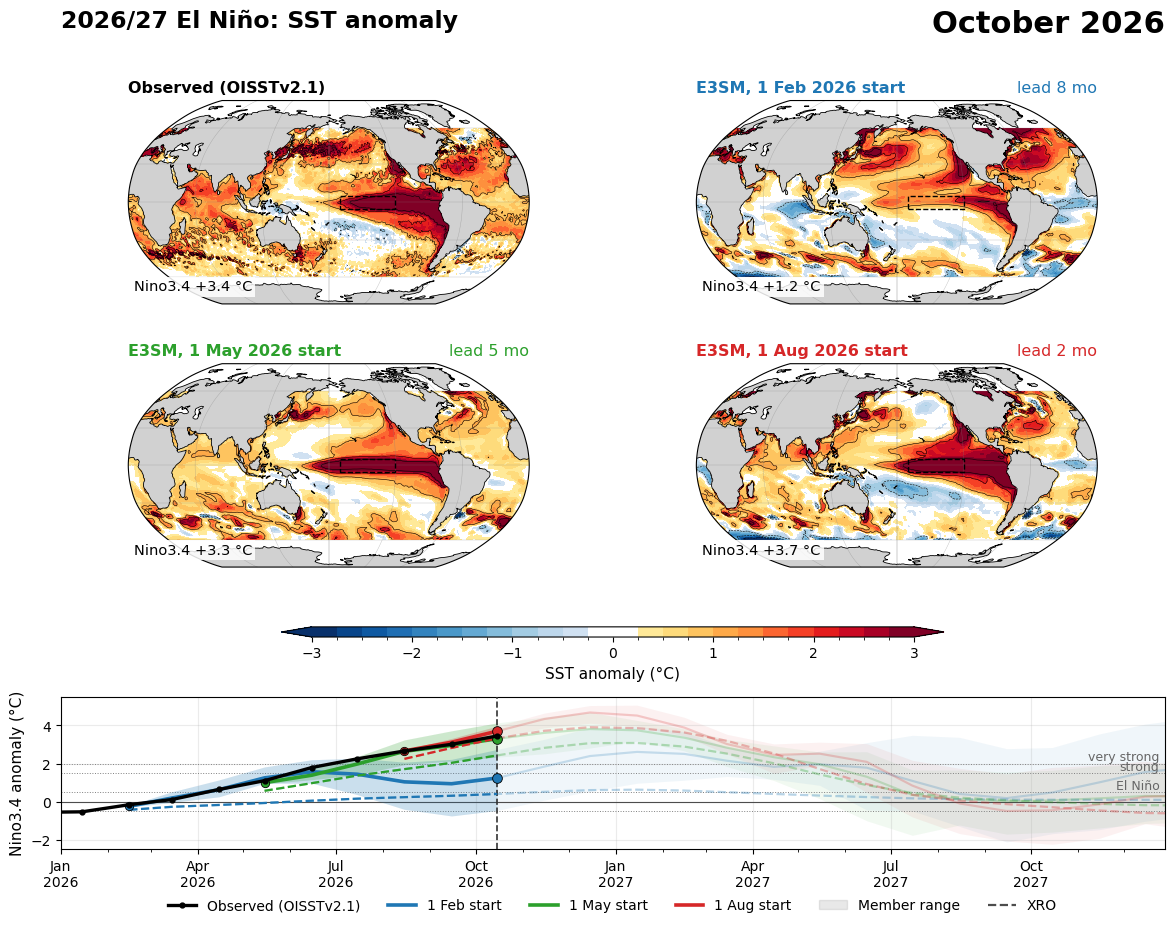

In [7]:
preview_month = datetime(2026, 10, 15)
fig, state = build_figure("TS")
draw_frame(state, preview_month)
plt.show()

### Animations

One GIF and one MP4 per field in `ANIM_FIELDS` under `figures/`. The months run from `FRAMES[0]` to
`FRAMES[1]`; the last month is held for `HOLD` frames.

video: webm


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_ts_evolution_nino3_4.gif (4.1 MB)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_ts_evolution_nino3_4.webm (1.3 MB)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_ohc700_evolution_nino3_4.gif (4.7 MB)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_ohc700_evolution_nino3_4.webm (1.6 MB)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_prect_evolution_nino3_4.gif (3.7 MB)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_prect_evolution_nino3_4.webm (0.6 MB)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_trefht_evolution_nino3_4.gif (3.1 MB)


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_trefht_evolution_nino3_4.webm (0.7 MB)


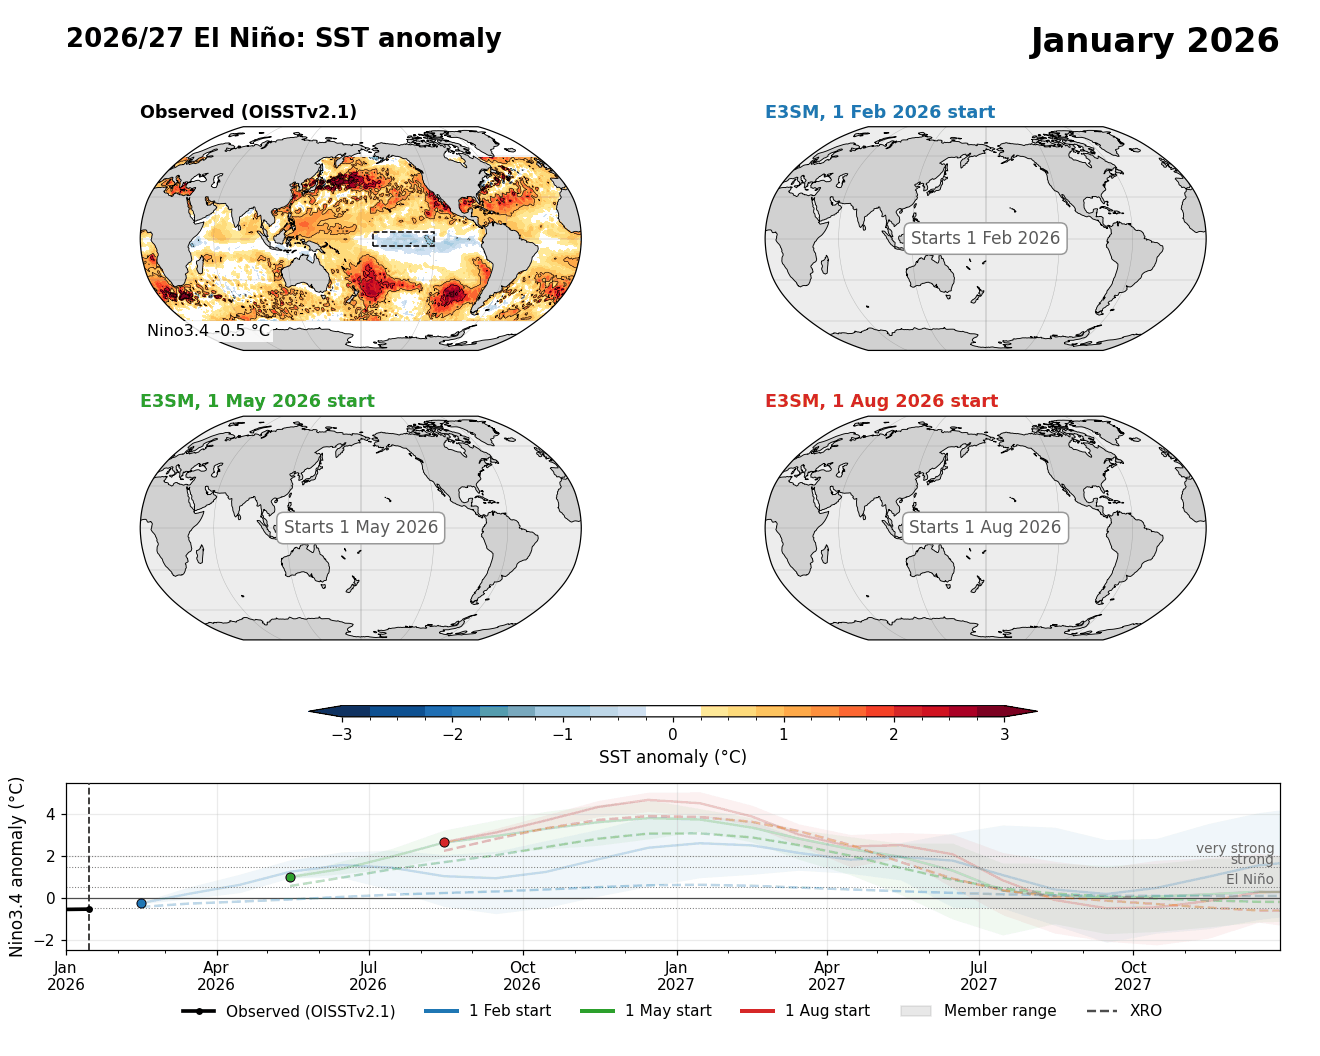

CPU times: user 32min 16s, sys: 31.8 s, total: 32min 47s
Wall time: 33min 21s


In [8]:
%%time
def video_writer():
    # (extension, writer factory) for the best video codec the available ffmpeg has, or (None, None)
    try:
        import imageio_ffmpeg   # bundled ffmpeg with H.264
        plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
    except ImportError:
        pass
    if not animation.writers.is_available("ffmpeg"):
        return None, None
    encoders = subprocess.run([plt.rcParams["animation.ffmpeg_path"], "-hide_banner", "-encoders"],
                              capture_output=True, text=True).stdout
    even = ["-vf", "scale=trunc(iw/2)*2:trunc(ih/2)*2", "-pix_fmt", "yuv420p"]
    if "libx264" in encoders:
        return "mp4", lambda: animation.FFMpegWriter(fps=FPS, codec="libx264", extra_args=even + ["-crf", "20"])
    if "libvpx-vp9" in encoders:
        return "webm", lambda: animation.FFMpegWriter(fps=FPS, codec="libvpx-vp9",
                                                      extra_args=even + ["-crf", "30", "-b:v", "0"])
    return None, None


anim_files = {}
video_ext, video = video_writer()
writers = {"gif": ("gif", lambda: animation.PillowWriter(fps=FPS)), "video": (video_ext, video)}
print(f"video: {video_ext or 'no ffmpeg video encoder; skipped'}")
months = frame_months(*FRAMES)
sequence = months + [months[-1]] * HOLD
for field in ANIM_FIELDS:
    fig, state = build_figure(field)
    anim = animation.FuncAnimation(fig, lambda t: draw_frame(state, t), frames=sequence, blit=False,
                                   cache_frame_data=False)
    for fmt in ANIM_FORMATS:
        ext, writer = writers[fmt]
        if writer is None:
            continue
        path = FIGDIR / figure_filename("RTENSO2026", f"y{YEAR}", field, "evolution", INDEX, ext=ext)
        anim.save(path, writer=writer(), dpi=ANIM_DPI)
        anim_files[(field, ext)] = path
        print(f"{path} ({path.stat().st_size / 1e6:.1f} MB)")
    plt.close(fig)

if SHOW_INLINE and (SHOW_INLINE, "gif") in anim_files:
    display(Image(filename=str(anim_files[(SHOW_INLINE, "gif")])))

### Storyboard

The same panels for the `STORYBOARD` months in one static figure (rows: months; columns: observed,
then each start), for papers and handouts.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_ts_storyboard.png


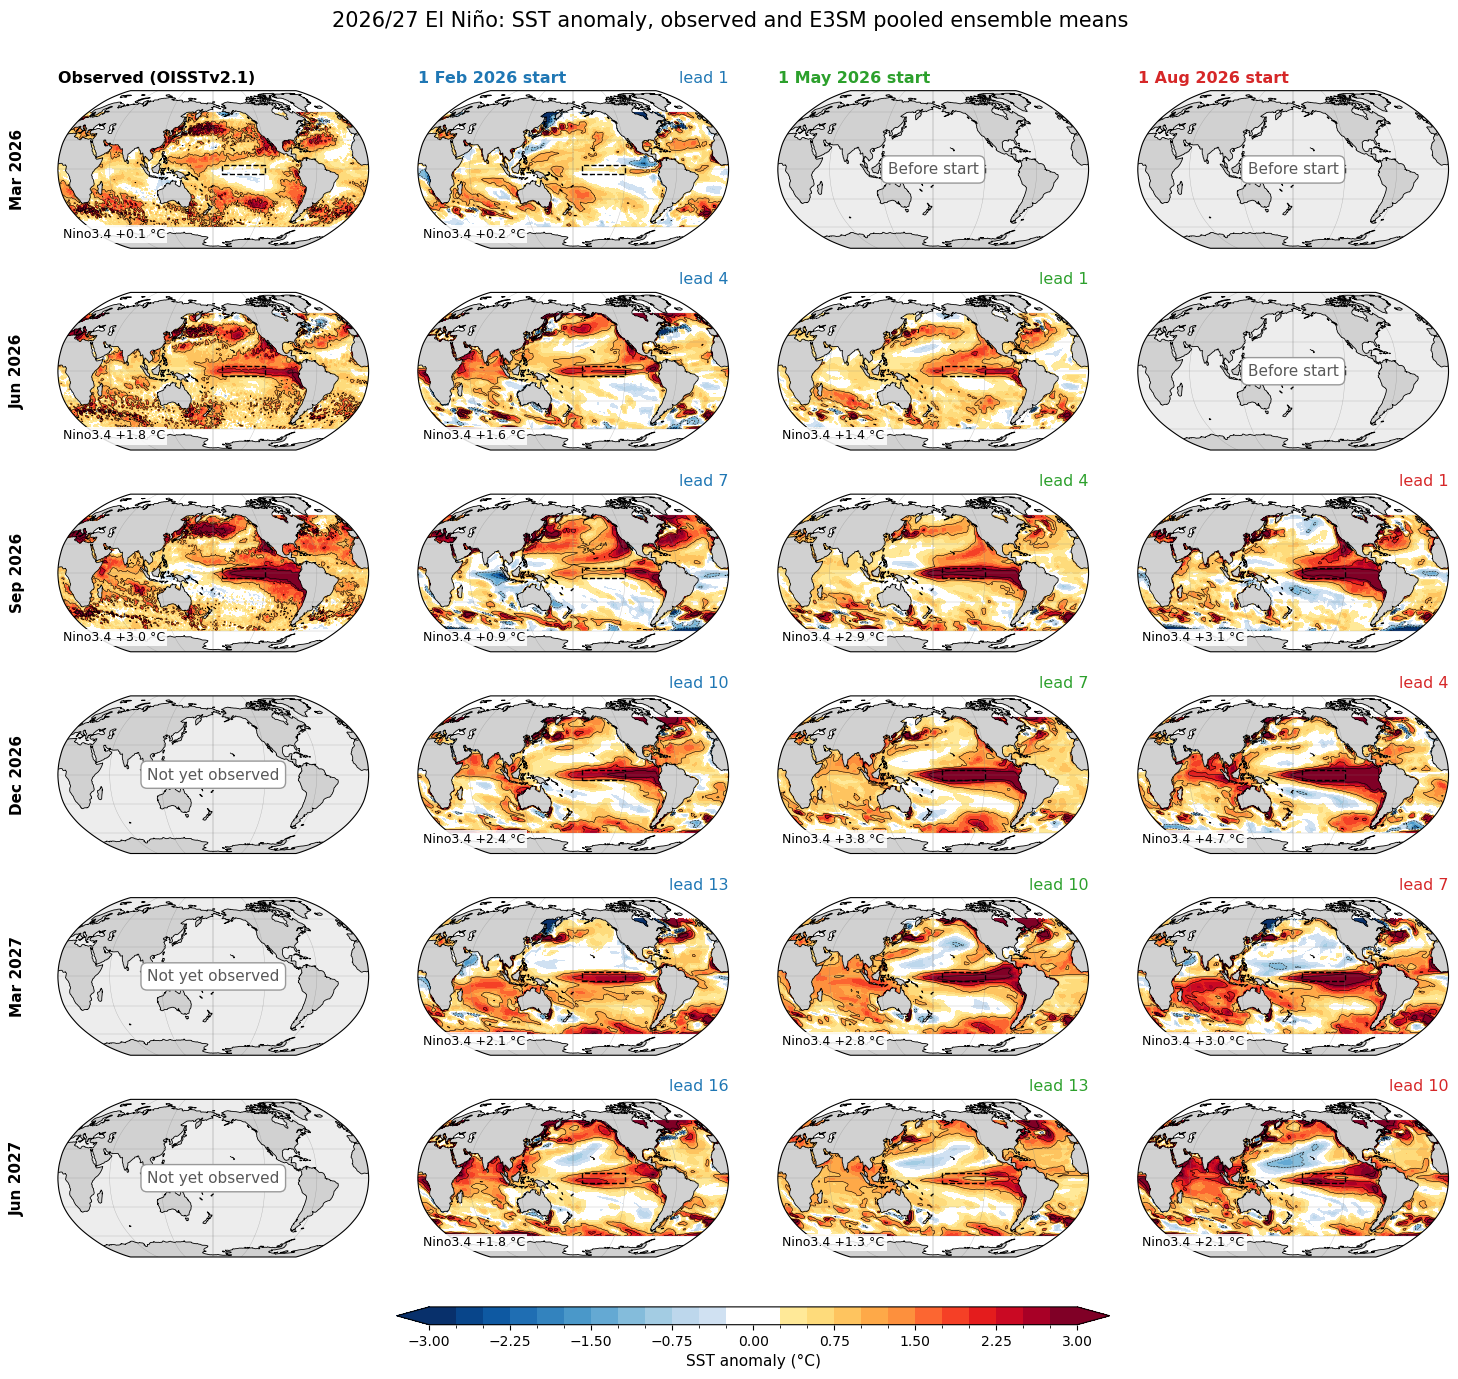

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_ohc700_storyboard.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_prect_storyboard.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/8_enso2026_animation/figures/fig_rtenso2026_y2026_trefht_storyboard.png


In [9]:
def storyboard(field):
    style = STYLE[field]
    inits = [i for i in INIT_MONTHS if (field, i) in fc]
    columns = [("obs", f"Observed ({obs[field].attrs['product'].replace('_', ' ')})", "k")]
    columns += [(i, f"1 {MONTH_NAMES[i]} {YEAR} start", INIT_COLORS[i]) for i in inits]
    rows = [datetime(y, m, 15) for y, m in STORYBOARD]
    panel = (4.6, 2.5) if GLOBAL else (4.6, 1.75)
    fig, axes = plt.subplots(len(rows), len(columns), figsize=(panel[0] * len(columns), panel[1] * len(rows) + 1.2),
                             subplot_kw={"projection": PROJ}, squeeze=False,
                             gridspec_kw={"hspace": 0.28, "wspace": 0.04})
    for r, t in enumerate(rows):
        for c, (key, title, color) in enumerate(columns):
            ax = axes[r, c]
            mstate = setup_map(ax, title if r == 0 else "", color, left=c == 0, bottom=r == len(rows) - 1,
                               land_only=style.get("land", False))
            mstate["badge"].set_fontsize(FIG["badge"] - 1.5)
            if key == "obs":
                da = field_at(obs[field], t)
                fill_map(ax, mstate, da, style, empty="Not yet observed",
                         badge=nino_badge(obs_value(obs_nino, t)) if da is not None else "")
            else:
                da = field_at(fc[(field, key)], t) if t >= datetime(YEAR, key, 15) else None
                lead = (t.year - YEAR) * 12 + t.month - key
                value = float(fc_nino[key].mean("member").sel(time=t)) if da is not None and key in fc_nino else None
                fill_map(ax, mstate, da, style, empty="Before start", lead=f"lead {lead}" if da is not None else "",
                         badge=nino_badge(value))
            if c == 0:
                ax.text(-0.13, 0.5, month_label(t), transform=ax.transAxes, rotation=90, ha="center", va="center",
                        fontsize=FIG["label"], fontweight="bold")
    levels, cmap, norm = levels_cmap(style)
    cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, orientation="horizontal", extend="both",
                        fraction=0.025, pad=0.04, shrink=0.5, aspect=40)
    cbar.set_label(f"{style['name']} ({style['units']})", fontsize=FIG["label"])
    cbar.ax.tick_params(labelsize=FIG["tick"])
    fig.suptitle(f"{EVENT_LABEL}: {style['name']}, observed and E3SM pooled ensemble means",
                 fontsize=FIG["suptitle"] - 2, y=0.93)
    return fig


for field in ANIM_FIELDS:
    fig = storyboard(field)
    print(rc.save_figure(fig, NOTEBOOK, "RTENSO2026", f"y{YEAR}", field, "storyboard", dpi=fig_dpi))
    if field == SHOW_INLINE:
        plt.show()
    else:
        plt.close(fig)